In [1]:
	
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import cv2
from sklearn.metrics import classification_report, confusion_matrix
from keras.callbacks import ReduceLROnPlateau
import os

2025-11-01 11:48:35.483442: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
labels = ['PNEUMONIA','NORMAL']
img_resize = 150

def get_data(dir):
  data = []
  for label in labels:
    path = os.path.join(dir, label)
    class_num = labels.index(label)

    for img in os.listdir(path):
      try:
        if img.endswith('jpeg'):
          img_arr = cv2.imread(os.path.join(path,img), cv2.IMREAD_GRAYSCALE)
          resized_arr = cv2.resize(img_arr, (img_resize, img_resize))
          data.append([resized_arr, class_num])
      except Exception as e:
        print(e)
  return np.array(data,dtype= 'object')



In [5]:

train = get_data('/Users/rwan/Desktop/chest_xray/chest_xray/train')
test = get_data('/Users/rwan/Desktop/chest_xray/chest_xray/test')
val = get_data('/Users/rwan/Desktop/chest_xray/chest_xray/val')


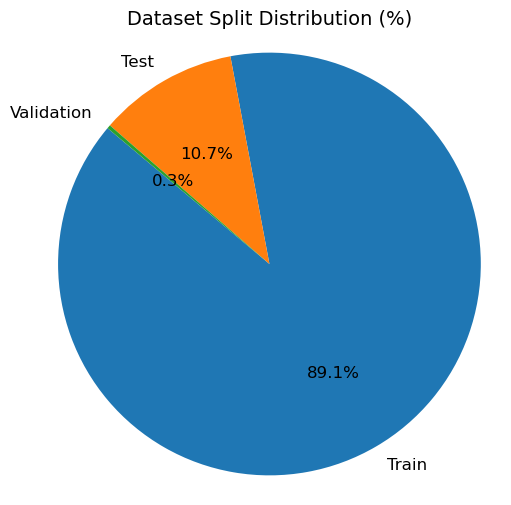

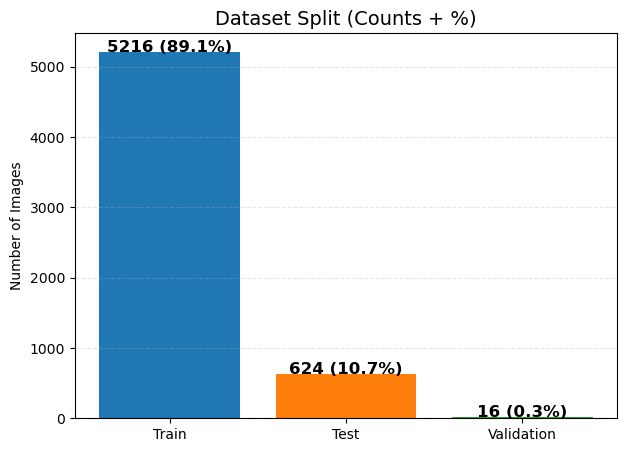

In [43]:
import matplotlib.pyplot as plt

# الحساب
sizes = [len(train), len(test), len(val)]
labels = ['Train', 'Test', 'Validation']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# الرسم 1: Pie Chart (النسب)
plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors,
        startangle=140, textprops={'fontsize': 12})
plt.title("Dataset Split Distribution (%)", fontsize=14)
plt.axis('equal')
plt.show()

# الرسم 2: Bar Chart (الأرقام + النسب)
plt.figure(figsize=(7,5))
bars = plt.bar(labels, sizes, color=colors)

# كتابة العدد والنسبة فوق الأعمدة
total = sum(sizes)
for bar, value in zip(bars, sizes):
    percent = value / total * 100
    plt.text(bar.get_x() + bar.get_width()/2, value + 2,
             f"{value} ({percent:.1f}%)",
             ha='center', fontsize=12, fontweight='bold')

plt.title("Dataset Split (Counts + %)", fontsize=14)
plt.ylabel("Number of Images")
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

<Axes: xlabel='count'>

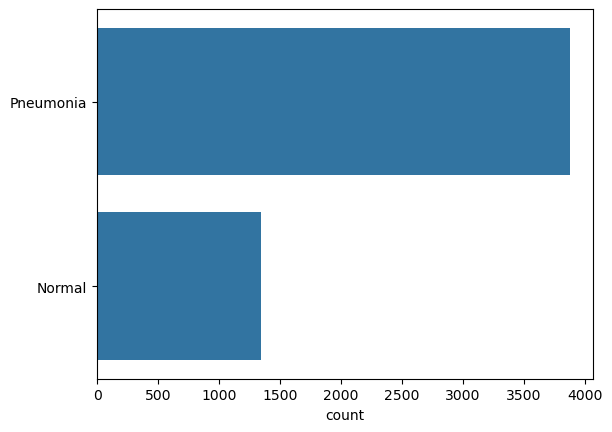

In [6]:

l = []
for i in train:
  if (i[1] == 0):
    l.append('Pneumonia')
  else:
    l.append('Normal')

sns.countplot(l)

In [44]:
import os
import cv2

def count_corrupted_images(path):
    missing = 0
    total = 0

    for folder in ['PNEUMONIA', 'NORMAL']:
        folder_path = os.path.join(path, folder)
        for img_name in os.listdir(folder_path):
            total += 1
            img_path = os.path.join(folder_path, img_name)
            img = cv2.imread(img_path)
            if img is None:
                missing += 1
    
    return missing, total

train_missing, train_total = count_corrupted_images("/Users/rwan/Desktop/chest_xray/chest_xray/train")
test_missing, test_total   = count_corrupted_images("/Users/rwan/Desktop/chest_xray/chest_xray/test")
val_missing, val_total     = count_corrupted_images("/Users/rwan/Desktop/chest_xray/chest_xray/val")

print("Train:", train_missing, "/", train_total)
print("Test:",  test_missing, "/", test_total)
print("Val:",   val_missing, "/", val_total)

Train: 2 / 5218
Test: 0 / 624
Val: 2 / 18


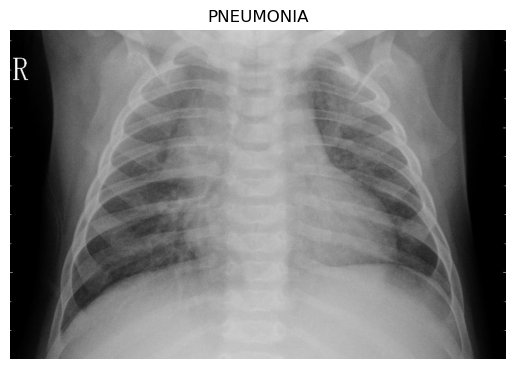

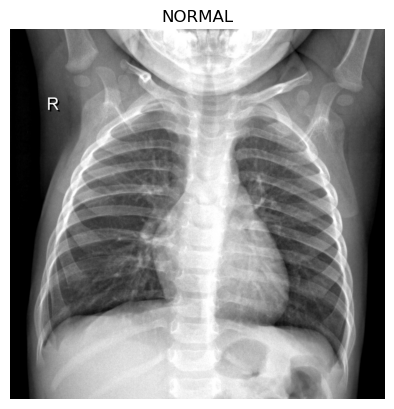

In [31]:

import random
import cv2
import matplotlib.pyplot as plt

path = "/Users/rwan/Desktop/chest_xray/chest_xray/train"

for label in ["PNEUMONIA", "NORMAL"]:
    img_name = random.choice(os.listdir(os.path.join(path, label)))
    img = cv2.cvtColor(cv2.imread(os.path.join(path, label, img_name)), cv2.COLOR_BGR2RGB)
    plt.figure()
    plt.title(label)
    plt.imshow(img)
    plt.axis('off')

plt.show()

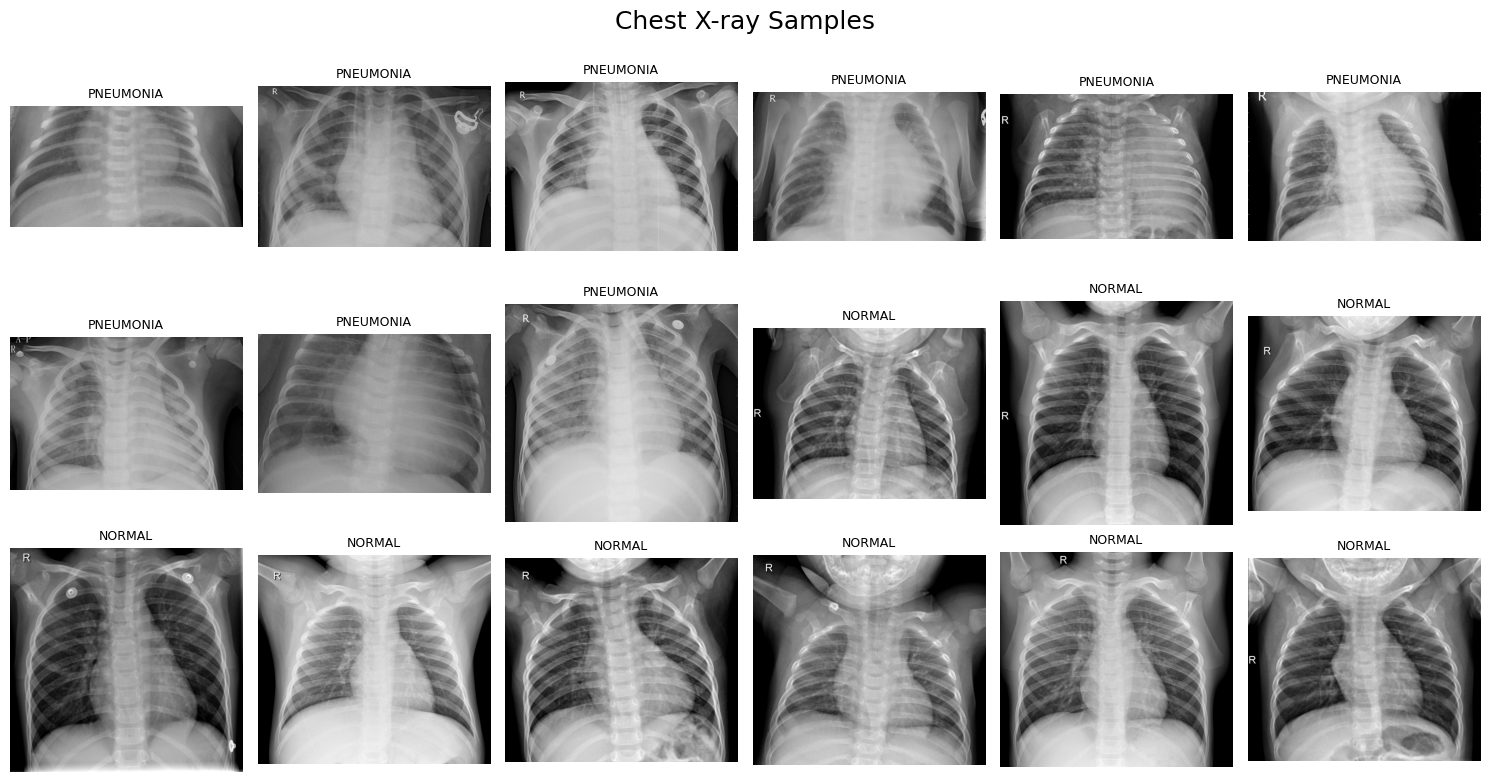

In [33]:
import os, random, cv2
import matplotlib.pyplot as plt

path = "/Users/rwan/Desktop/chest_xray/chest_xray/train"

labels = ["PNEUMONIA", "NORMAL"]
images = []

# نختار 9 صور لكل نوع
for label in labels:
    folder = os.path.join(path, label)
    chosen = random.sample(os.listdir(folder), 9)
    for img_name in chosen:
        images.append((label, os.path.join(folder, img_name)))

plt.figure(figsize=(15, 8))
plt.suptitle("Chest X-ray Samples", fontsize=18)

for i, (label, img_path) in enumerate(images):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    plt.subplot(3, 6, i+1)
    plt.imshow(img)
    plt.title(label, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:

x_train = []
y_train = []

x_val = []
y_val = []

x_test = []
y_test = []

for feat, label in train:
  x_train.append(feat)
  y_train.append(label)

for feat,label in val:
  x_val.append(feat)
  y_val.append(label)

for feat, label in test:
  x_test.append(feat)
  y_test.append(label)

In [9]:
#Normalize the data
x_train = np.array(x_train)/255
x_val = np.array(x_val)/255
x_test = np.array(x_test)/255
     

In [10]:
x_train

array([[[0.80392157, 0.81176471, 0.78823529, ..., 0.76470588,
         0.76862745, 0.82352941],
        [0.8       , 0.8       , 0.80392157, ..., 0.77254902,
         0.77254902, 0.82745098],
        [0.80392157, 0.8       , 0.79607843, ..., 0.8       ,
         0.82352941, 0.84313725],
        ...,
        [0.07058824, 0.05098039, 0.03529412, ..., 0.18431373,
         0.19607843, 0.2       ],
        [0.05098039, 0.05098039, 0.03921569, ..., 0.18431373,
         0.18431373, 0.19607843],
        [0.05098039, 0.05098039, 0.03921569, ..., 0.17254902,
         0.17647059, 0.18431373]],

       [[0.        , 0.03529412, 0.07058824, ..., 0.25098039,
         0.19607843, 0.18431373],
        [0.00784314, 0.05490196, 0.09019608, ..., 0.21176471,
         0.21176471, 0.20392157],
        [0.02352941, 0.05882353, 0.09411765, ..., 0.21568627,
         0.22352941, 0.20392157],
        ...,
        [0.        , 0.00784314, 0.18823529, ..., 0.        ,
         0.        , 0.        ],
        [0. 

In [11]:
x_train = x_train.reshape(-1,img_resize, img_resize,1)
y_train = np.array(y_train)

x_val = x_val.reshape(-1,img_resize,img_resize,1)
y_val = np.array(y_val)


x_test = x_test.reshape(-1,img_resize,img_resize,1)
y_test = np.array(y_test)

In [12]:

datagen = ImageDataGenerator(
    featurewise_center=False,
    samplewise_center=False,
    featurewise_std_normalization=False,
    samplewise_std_normalization=False,
    zca_whitening=False,
    rotation_range=30,
    width_shift_range = 0.1,
    height_shift_range = 0.1,
    zoom_range = 0.2,
    horizontal_flip=True,
    vertical_flip=False
)

datagen.fit(x_train)
     

In [13]:
model = Sequential()
model.add(Conv2D(32,(3,3), strides =1, padding='same', activation='relu', input_shape=(150,150,1)))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2),strides=2,padding='same'))
model.add(Conv2D(64,(3,3), strides =1, padding='same', activation='relu'))
model.add(Dropout(0.1))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2),strides=2,padding='same'))
model.add(Conv2D(64,(3,3), strides =1, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2),strides=2,padding='same'))
model.add(Conv2D(128,(3,3), strides =1, padding='same', activation='relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2),strides=2,padding='same'))
model.add(Conv2D(256,(3,3), strides =1, padding='same', activation='relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2),strides=2,padding='same'))
model.add(Flatten())
model.add(Dense(units=128,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(units=1,activation='sigmoid'))
model.compile(optimizer='rmsprop',loss='binary_crossentropy',metrics=['accuracy']) #rmsprop
model.summary()


/Users/rwan/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 38, 38, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 38, 38, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 19, 19, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 19, 19, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 19, 19, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 19, 19, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 1,246,401 (4.75 MB)

 Trainable params: 1,245,313 (4.75 MB)

 Non-trainable params: 1,088 (4.25 KB)

In [14]:
learning_rate_reduction = ReduceLROnPlateau(monitor='val_accuracy',patience=2,verbose=1,factor=0.3,min_lr=0.000001)
     


In [15]:

history = model.fit(x_train,y_train,batch_size=32,epochs=18,
                    validation_data=datagen.flow(x_val,y_val),
                    callbacks=[learning_rate_reduction])
     

Epoch 1/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8362 - loss: 1.1760

/Users/rwan/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


163/163 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.8863 - loss: 0.4835 - val_accuracy: 0.5000 - val_loss: 16.7538 - learning_rate: 0.0010
Epoch 2/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.9563 - loss: 0.1409 - val_accuracy: 0.5000 - val_loss: 19.8201 - learning_rate: 0.0010
Epoch 3/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9671 - loss: 0.0890
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
163/163 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.9668 - loss: 0.0955 - val_accuracy: 0.5000 - val_loss: 29.8663 - learning_rate: 0.0010
Epoch 4/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.9870 - loss: 0.0391 - val_accuracy: 0.5000 - val_loss: 12.7346 - learning_rate: 3.0000e-04
Epoch 5/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 999ms/step - accuracy: 0.9916 - loss: 0.0236
Epoch 5: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
163/163 ━━━━━━━━━━━━━━━━━━━━ 163s 1s/step - accuracy: 0.9919 - loss: 0.0237 -

In [16]:
model.evaluate(x_test,y_test)

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 192ms/step - accuracy: 0.7356 - loss: 2.8690


[2.8689961433410645, 0.7355769276618958]

In [17]:

print(f"Loss of the model is {model.evaluate(x_test,y_test)[0]}")
print(f"Accuracy of the model is {model.evaluate(x_test,y_test)[1]*100} %")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 193ms/step - accuracy: 0.7356 - loss: 2.8690
Loss of the model is 2.8689961433410645
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 200ms/step - accuracy: 0.7356 - loss: 2.8690
Accuracy of the model is 73.55769276618958 %


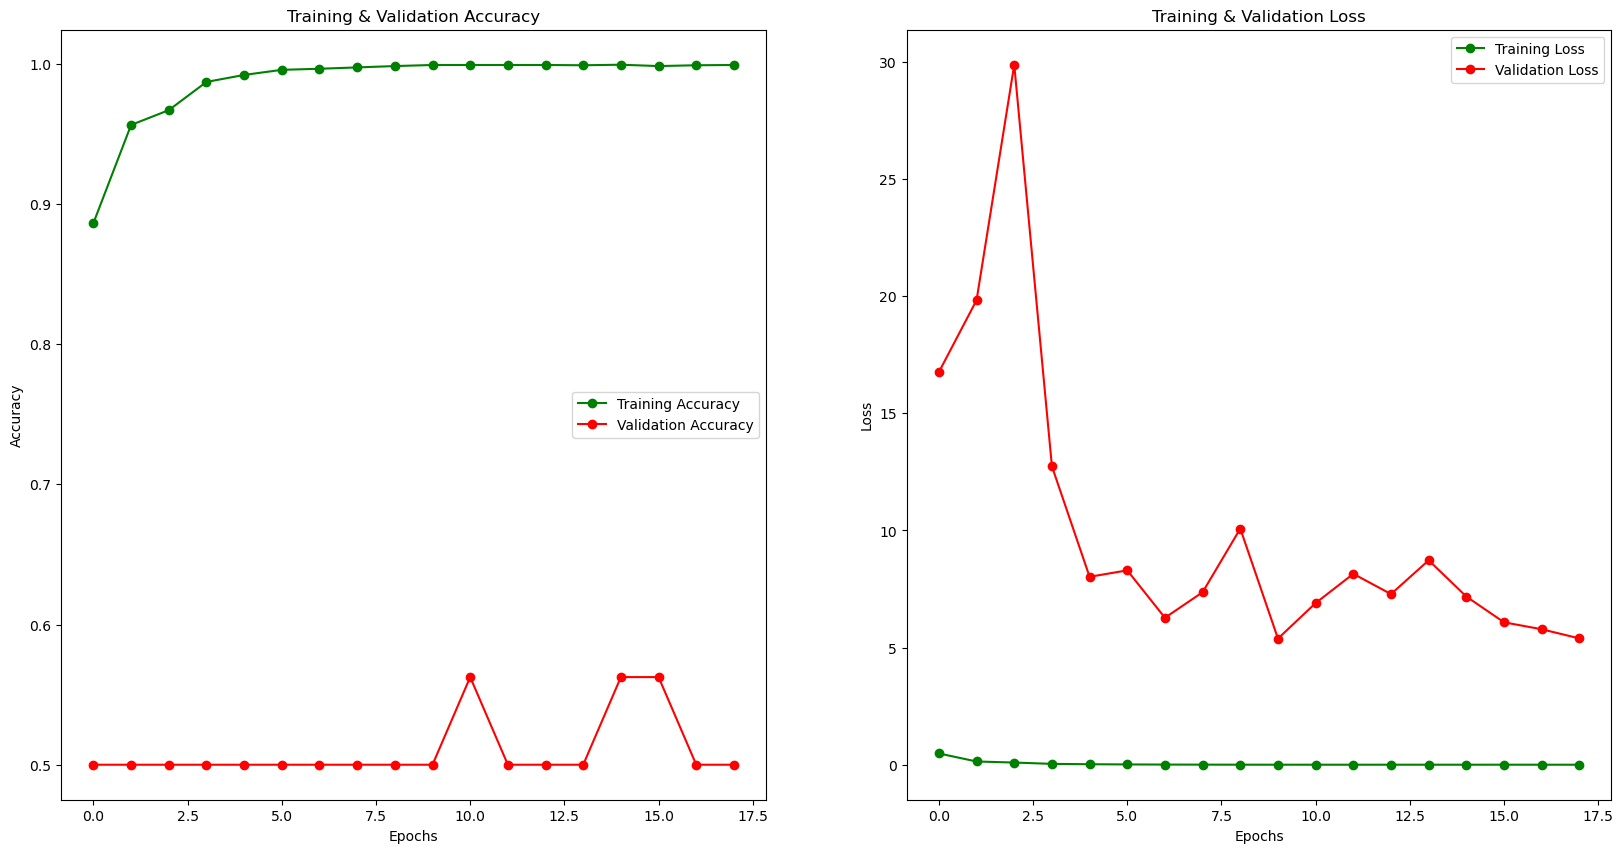

In [18]:
epochs = [i for i in range(18)]
fig, ax = plt.subplots(1,2)
train_acc = history.history['accuracy']
train_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

fig.set_size_inches(20,10)

ax[0].plot(epochs, train_acc, 'go-', label='Training Accuracy')
ax[0].plot(epochs, val_acc, 'ro-', label='Validation Accuracy')
ax[0].set_title('Training & Validation Accuracy')
ax[0].legend()
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Accuracy')


ax[1].plot(epochs, train_loss, 'g-o', label='Training Loss')
ax[1].plot(epochs, val_loss, 'r-o', label='Validation Loss')
ax[1].set_title('Training & Validation Loss')
ax[1].legend()
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss')
plt.show()

In [19]:
predictions = (model.predict(x_test) > 0.5).astype('int32')
predictions = predictions.reshape(1,-1)[0]
predictions[:15]

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 225ms/step


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [20]:
print(classification_report(y_test, predictions, target_names=['Pneumonia (Class 0)', 'Normal (Class 1)']))
     

                     precision    recall  f1-score   support

Pneumonia (Class 0)       0.70      1.00      0.83       390
   Normal (Class 1)       1.00      0.29      0.46       234

           accuracy                           0.74       624
          macro avg       0.85      0.65      0.64       624
       weighted avg       0.81      0.74      0.69       624



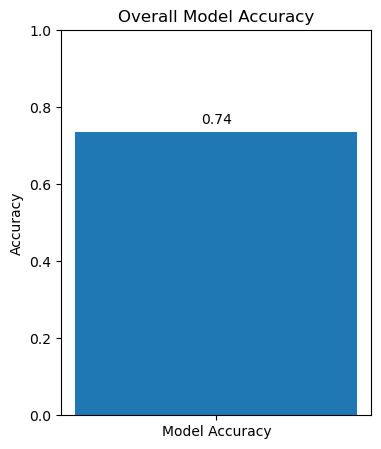

In [37]:
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test, predictions)

plt.figure(figsize=(4,5))
plt.bar(['Model Accuracy'], [accuracy])
plt.ylim(0, 1)
plt.title('Overall Model Accuracy')
plt.ylabel('Accuracy')
plt.text(0, accuracy + 0.02, f"{accuracy:.2f}", ha='center')
plt.show()

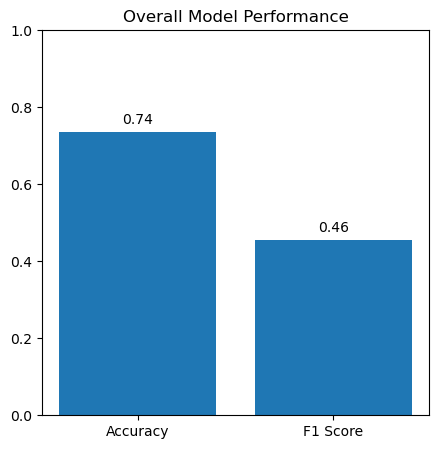

In [39]:
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

acc = accuracy_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

metrics = ['Accuracy', 'F1 Score']
values = [acc, f1]

plt.figure(figsize=(5,5))
plt.bar(metrics, values)
plt.ylim(0, 1)
plt.title("Overall Model Performance")
for i, v in enumerate(values):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center')
plt.show()

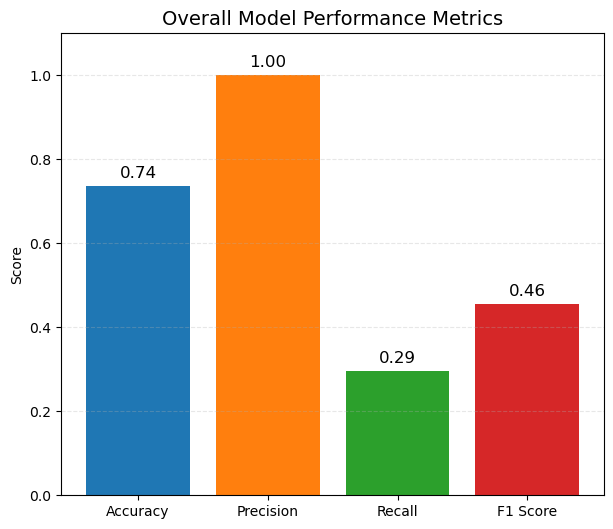

In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# حساب المقاييس
acc = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
values = [acc, precision, recall, f1]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # ألوان مختلفة لكل مقياس

plt.figure(figsize=(7,6))
bars = plt.bar(metrics, values, color=colors)

# كتابة النسب فوق الأعمدة
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2,
             value + 0.02,
             f"{value:.2f}",
             ha='center', fontsize=12)

plt.ylim(0, 1.1)
plt.title("Overall Model Performance Metrics", fontsize=14)
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

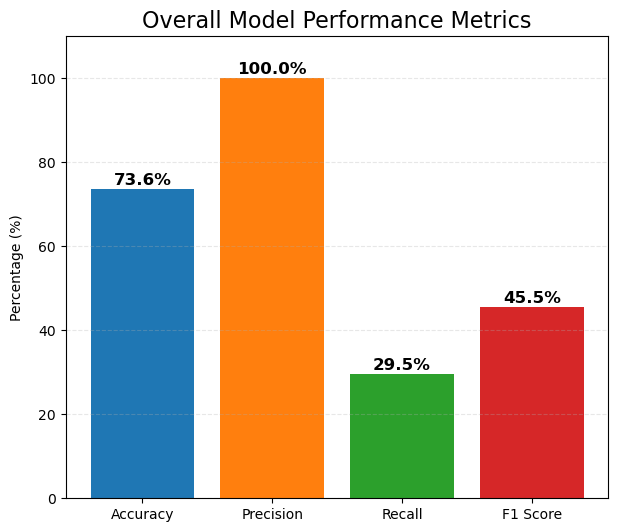

In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# حساب المقاييس
acc = accuracy_score(y_test, predictions) * 100
precision = precision_score(y_test, predictions) * 100
recall = recall_score(y_test, predictions) * 100
f1 = f1_score(y_test, predictions) * 100

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
values = [acc, precision, recall, f1]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # 4 ألوان مختلفة

plt.figure(figsize=(7,6))
bars = plt.bar(metrics, values, color=colors)

# كتابة النسبة فوق كل عمود
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2,
             value + 1,
             f"{value:.1f}%",
             ha='center', fontsize=12, fontweight='bold')

plt.ylim(0, 110)
plt.title("Overall Model Performance Metrics", fontsize=16)
plt.ylabel("Percentage (%)")
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

In [21]:
cm = confusion_matrix(y_test,predictions)

In [22]:
cm

array([[390,   0],
       [165,  69]])

In [23]:

correct = np.nonzero(predictions == y_test)[0]
incorrect = np.nonzero(predictions != y_test)[0]

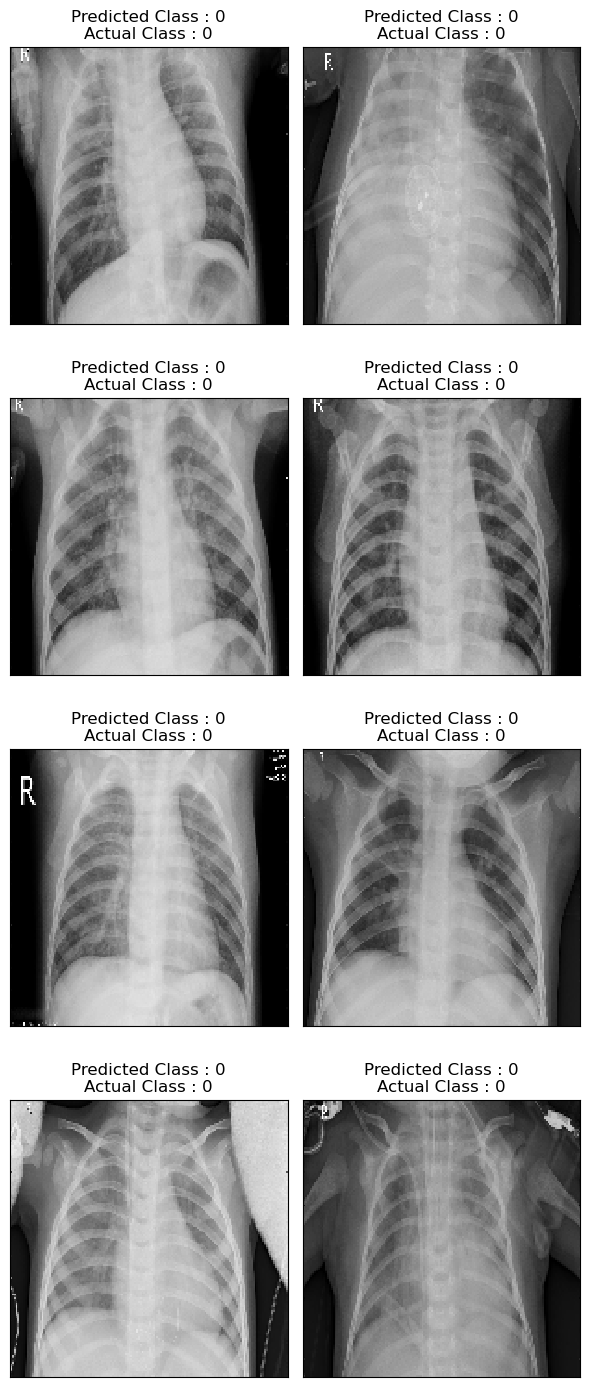

In [24]:

i = 0
plt.figure(figsize=(6,15))
for c in correct[10:18]:
  plt.subplot(4,2,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(x_test[c].reshape(150,150), cmap='gray', interpolation='none')
  plt.title(f"Predicted Class : {predictions[c]}\nActual Class : {y_test[c]}")
  plt.tight_layout()
  i += 1


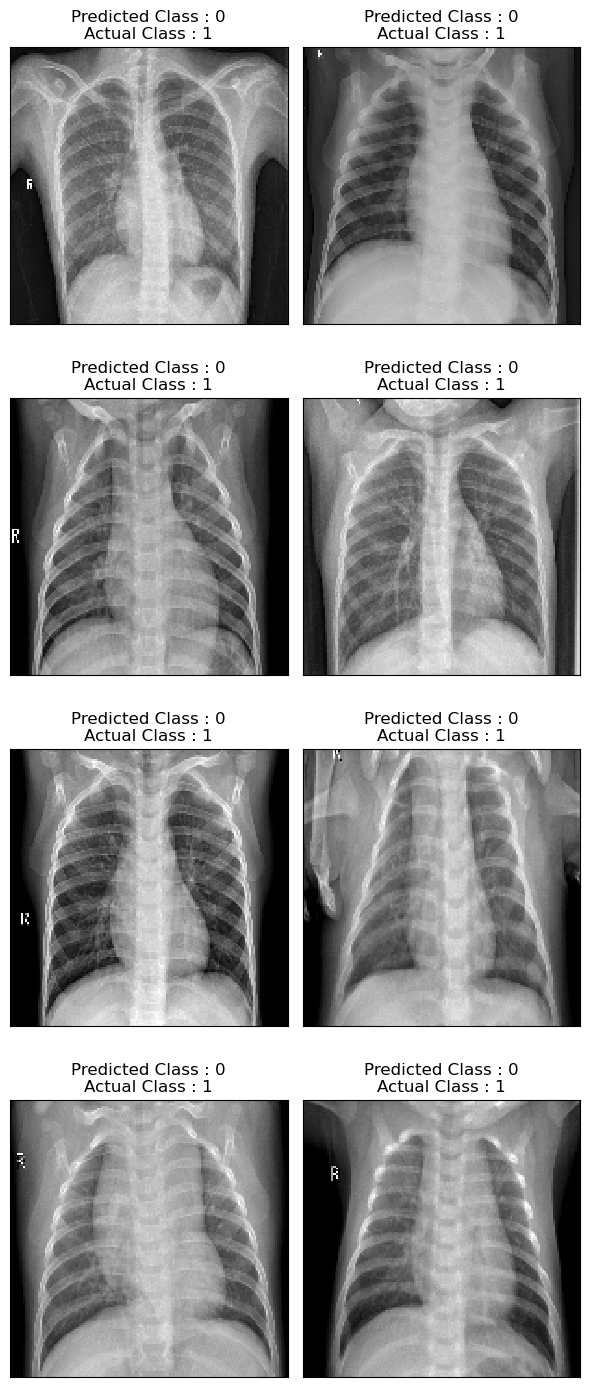

In [25]:

i = 0
plt.figure(figsize=(6,15))
for c in incorrect[10:18]:
  plt.subplot(4,2,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(x_test[c].reshape(150,150), cmap='gray', interpolation='none')
  plt.title(f"Predicted Class : {predictions[c]}\nActual Class : {y_test[c]}")
  plt.tight_layout()
  i += 1
     

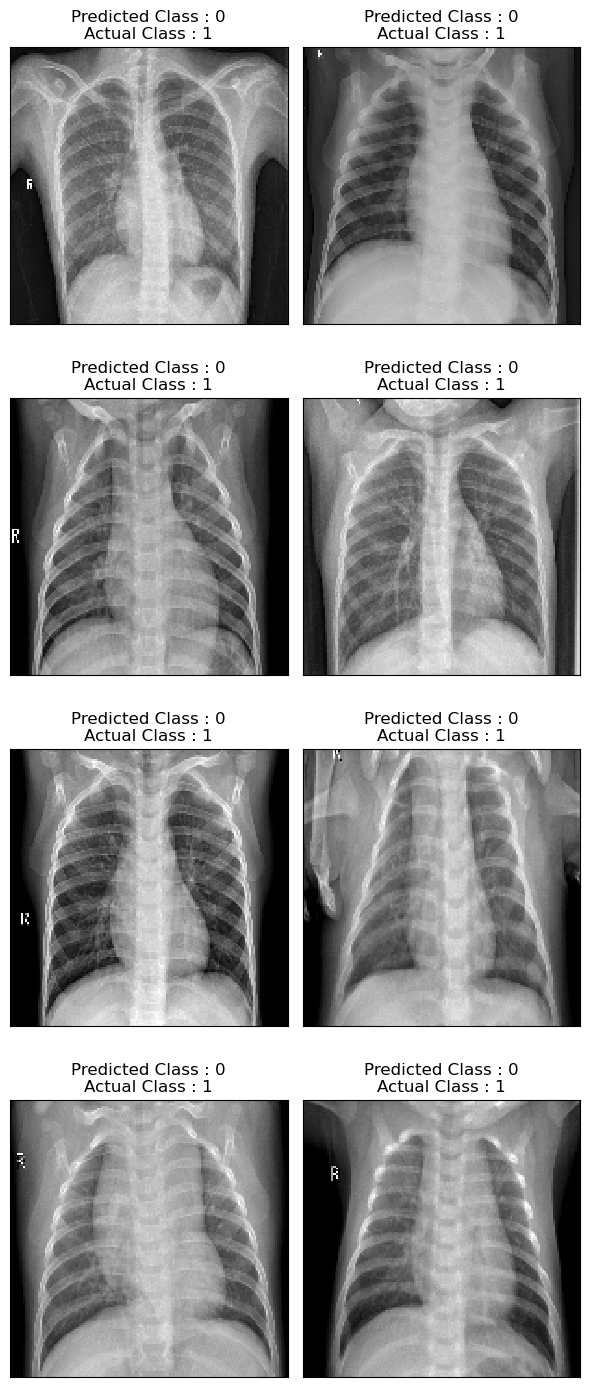

In [26]:
#Some Incorrectly Predicted Classes

i = 0
plt.figure(figsize=(6,15))
for c in incorrect[10:18]:
  plt.subplot(4,2,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(x_test[c].reshape(150,150), cmap='gray', interpolation='none')
  plt.title(f"Predicted Class : {predictions[c]}\nActual Class : {y_test[c]}")
  plt.tight_layout()
  i += 1